### Imports

In [8]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

### Configuration des chemins

In [9]:
DATA_RAW = Path("../data/raw")

### 1. Lister l'ensemble des CSV disponibles

In [10]:
csv_files = sorted(DATA_RAW.rglob("*.csv"))
print("Fichiers trouvés :")
for f in csv_files:
    print(f"- {f.relative_to(DATA_RAW)}")

Fichiers trouvés :
- Agriculture_Crop_Yield\crop_yield.csv
- Crop_Yield_Prediction_Dataset\pesticides.csv
- Crop_Yield_Prediction_Dataset\rainfall.csv
- Crop_Yield_Prediction_Dataset\temp.csv
- Crop_Yield_Prediction_Dataset\yield.csv
- Crop_Yield_Prediction_Dataset\yield_df.csv


### 2. Aperçu rapide des colonnes et des premières lignes de chaque fichier

In [11]:
dfs = {}
for file_path in csv_files:
    key = file_path.stem
    df = pd.read_csv(file_path)
    dfs[key] = df
    print(f"\n{'='*20} {key} (forme : {df.shape}) {'='*20}")
    print(f"Colonnes : {list(df.columns)}")
    display(df.head(2))


==================== crop_yield (forme : (1000000, 10)) ====================
Colonnes : ['Region', 'Soil_Type', 'Crop', 'Rainfall_mm', 'Temperature_Celsius', 'Fertilizer_Used', 'Irrigation_Used', 'Weather_Condition', 'Days_to_Harvest', 'Yield_tons_per_hectare']


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,West,Sandy,Cotton,897.077239,27.676966,False,True,Cloudy,122,6.555816
1,South,Clay,Rice,992.673282,18.026142,True,True,Rainy,140,8.527341



==================== pesticides (forme : (4349, 7)) ====================
Colonnes : ['Domain', 'Area', 'Element', 'Item', 'Year', 'Unit', 'Value']


,Domain,Area,Element,Item,Year,Unit,Value
0,Pesticides Use,Albania,Use,Pesticides (total),1990,tonnes of active ingredients,121.0
1,Pesticides Use,Albania,Use,Pesticides (total),1991,tonnes of active ingredients,121.0



==================== rainfall (forme : (6727, 3)) ====================
Colonnes : [' Area', 'Year', 'average_rain_fall_mm_per_year']


,Area,Year,average_rain_fall_mm_per_year
0,Afghanistan,1985,327
1,Afghanistan,1986,327


... (2 outputs left out)


==================== yield (forme : (56717, 12)) ====================
Colonnes : ['Domain Code', 'Domain', 'Area Code', 'Area', 'Element Code', 'Element', 'Item Code', 'Item', 'Year Code', 'Year', 'Unit', 'Value']


,Domain Code,Domain,Area Code,Area,Element Code,Element,Item Code,Item,Year Code,Year,Unit,Value
0,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1961,1961,hg/ha,14000
1,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1962,1962,hg/ha,14000



==================== yield_df (forme : (28242, 8)) ====================
Colonnes : ['Unnamed: 0', 'Area', 'Item', 'Year', 'hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']


,Unnamed: 0,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37


### 3. Vérification des types et des valeurs manquantes par table

In [12]:
for name, df in dfs.items():
    print(f"\n--- Infos : {name} ---")
    missing = df.isnull().sum()
    print("Valeurs manquantes par colonne :")
    print(missing[missing > 0] if missing.sum() > 0 else "Aucune valeur manquante")


--- Infos : crop_yield ---
Valeurs manquantes par colonne :
Aucune valeur manquante

--- Infos : pesticides ---
Valeurs manquantes par colonne :
Aucune valeur manquante

--- Infos : rainfall ---
Valeurs manquantes par colonne :
average_rain_fall_mm_per_year    774
dtype: int64

--- Infos : temp ---
Valeurs manquantes par colonne :
avg_temp    2547
dtype: int64

--- Infos : yield ---
Valeurs manquantes par colonne :
Aucune valeur manquante

--- Infos : yield_df ---
Valeurs manquantes par colonne :
Aucune valeur manquante


In [13]:
# 4. Qualité des données : Doublons et anomalies
doublons = dfs['crop_yield'].duplicated().sum()
print(f"Nombre de lignes dupliquées : {doublons}")

# Filtrage des rendements négatifs (et suppression des doublons si existants)
df_crop_clean = dfs['crop_yield'].drop_duplicates()
df_crop_clean = df_crop_clean[df_crop_clean['Yield_tons_per_hectare'] >= 0]

print(f"Taille du dataset après nettoyage : {df_crop_clean.shape}")

Nombre de lignes dupliquées : 0
Taille du dataset après nettoyage : (999769, 10)


### Imports

In [14]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

### Configuration des chemins

In [15]:
DATA_RAW = Path("../data/raw")

### 1. Lister l'ensemble des CSV disponibles

In [16]:
csv_files = sorted(DATA_RAW.rglob("*.csv"))
print("Fichiers trouvés :")
for f in csv_files:
    print(f"- {f.relative_to(DATA_RAW)}")

Fichiers trouvés :
- Agriculture_Crop_Yield\crop_yield.csv
- Crop_Yield_Prediction_Dataset\pesticides.csv
- Crop_Yield_Prediction_Dataset\rainfall.csv
- Crop_Yield_Prediction_Dataset\temp.csv
- Crop_Yield_Prediction_Dataset\yield.csv
- Crop_Yield_Prediction_Dataset\yield_df.csv


### 2. Aperçu rapide des colonnes et des premières lignes de chaque fichier

In [17]:
dfs = {}
for file_path in csv_files:
    key = file_path.stem
    df = pd.read_csv(file_path)
    dfs[key] = df
    print(f"\n{'='*20} {key} (forme : {df.shape}) {'='*20}")
    print(f"Colonnes : {list(df.columns)}")
    display(df.head(2))


==================== crop_yield (forme : (1000000, 10)) ====================
Colonnes : ['Region', 'Soil_Type', 'Crop', 'Rainfall_mm', 'Temperature_Celsius', 'Fertilizer_Used', 'Irrigation_Used', 'Weather_Condition', 'Days_to_Harvest', 'Yield_tons_per_hectare']


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,West,Sandy,Cotton,897.077239,27.676966,False,True,Cloudy,122,6.555816
1,South,Clay,Rice,992.673282,18.026142,True,True,Rainy,140,8.527341



==================== pesticides (forme : (4349, 7)) ====================
Colonnes : ['Domain', 'Area', 'Element', 'Item', 'Year', 'Unit', 'Value']


,Domain,Area,Element,Item,Year,Unit,Value
0,Pesticides Use,Albania,Use,Pesticides (total),1990,tonnes of active ingredients,121.0
1,Pesticides Use,Albania,Use,Pesticides (total),1991,tonnes of active ingredients,121.0



==================== rainfall (forme : (6727, 3)) ====================
Colonnes : [' Area', 'Year', 'average_rain_fall_mm_per_year']


,Area,Year,average_rain_fall_mm_per_year
0,Afghanistan,1985,327
1,Afghanistan,1986,327


... (2 outputs left out)


==================== yield (forme : (56717, 12)) ====================
Colonnes : ['Domain Code', 'Domain', 'Area Code', 'Area', 'Element Code', 'Element', 'Item Code', 'Item', 'Year Code', 'Year', 'Unit', 'Value']


,Domain Code,Domain,Area Code,Area,Element Code,Element,Item Code,Item,Year Code,Year,Unit,Value
0,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1961,1961,hg/ha,14000
1,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1962,1962,hg/ha,14000



==================== yield_df (forme : (28242, 8)) ====================
Colonnes : ['Unnamed: 0', 'Area', 'Item', 'Year', 'hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']


,Unnamed: 0,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37


### 3. Vérification des types et des valeurs manquantes par table

In [18]:
for name, df in dfs.items():
    print(f"\n--- Infos : {name} ---")
    missing = df.isnull().sum()
    print("Valeurs manquantes par colonne :")
    print(missing[missing > 0] if missing.sum() > 0 else "Aucune valeur manquante")


--- Infos : crop_yield ---
Valeurs manquantes par colonne :
Aucune valeur manquante

--- Infos : pesticides ---
Valeurs manquantes par colonne :
Aucune valeur manquante

--- Infos : rainfall ---
Valeurs manquantes par colonne :
average_rain_fall_mm_per_year    774
dtype: int64

--- Infos : temp ---
Valeurs manquantes par colonne :
avg_temp    2547
dtype: int64

--- Infos : yield ---
Valeurs manquantes par colonne :
Aucune valeur manquante

--- Infos : yield_df ---
Valeurs manquantes par colonne :
Aucune valeur manquante


In [19]:
# 4. Qualité des données : Doublons et anomalies
doublons = dfs['crop_yield'].duplicated().sum()
print(f"Nombre de lignes dupliquées : {doublons}")

# Filtrage des rendements négatifs (et suppression des doublons si existants)
df_crop_clean = dfs['crop_yield'].drop_duplicates()
df_crop_clean = df_crop_clean[df_crop_clean['Yield_tons_per_hectare'] >= 0]

print(f"Taille du dataset après nettoyage : {df_crop_clean.shape}")

Nombre de lignes dupliquées : 0
Taille du dataset après nettoyage : (999769, 10)


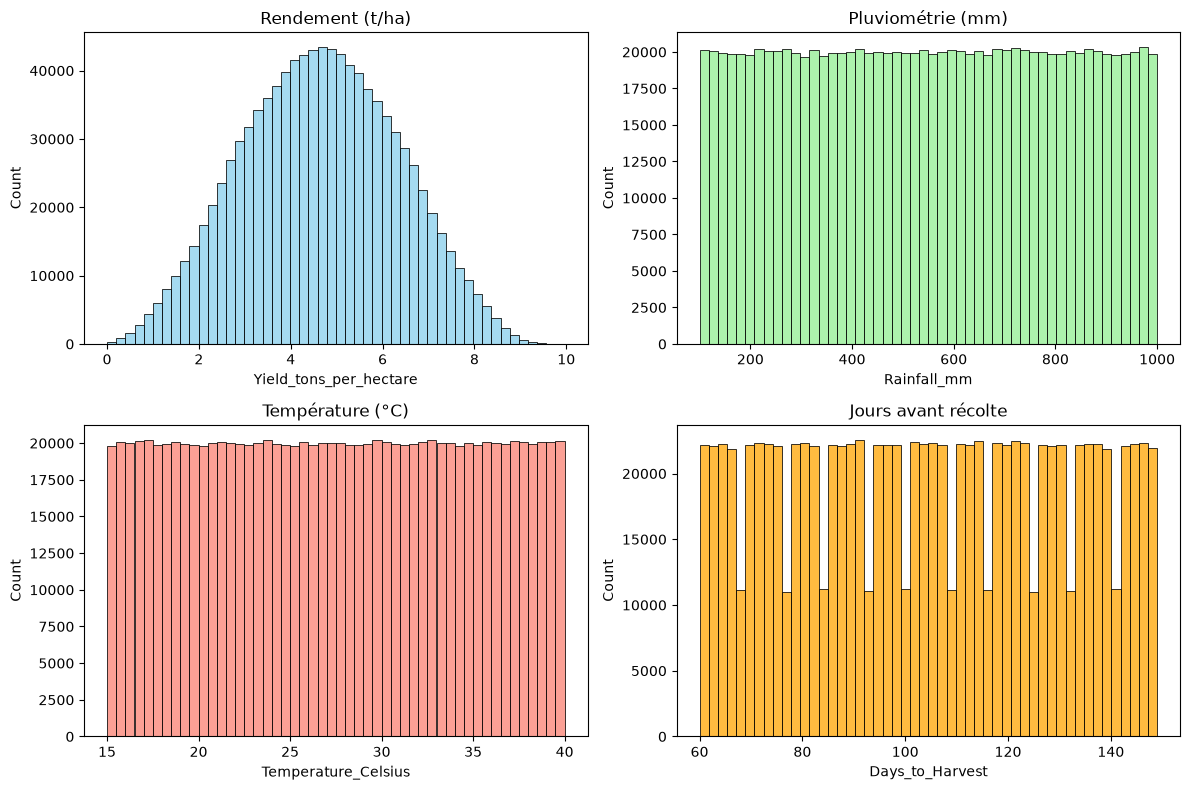

In [20]:
# 5. Distributions (Analyse univariée)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df_crop_clean['Yield_tons_per_hectare'], bins=50, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Rendement (t/ha)')

sns.histplot(df_crop_clean['Rainfall_mm'], bins=50, ax=axes[0, 1], color='lightgreen')
axes[0, 1].set_title('Pluviométrie (mm)')

sns.histplot(df_crop_clean['Temperature_Celsius'], bins=50, ax=axes[1, 0], color='salmon')
axes[1, 0].set_title('Température (°C)')

sns.histplot(df_crop_clean['Days_to_Harvest'], bins=50, ax=axes[1, 1], color='orange')
axes[1, 1].set_title('Jours avant récolte')

plt.tight_layout()
plt.show()

---
# approfondissement

qualité détaillée, effet de chaque variable, interactions, corrélations, ACP, validation sur `yield_df`, export.

In [21]:
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

SEED = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

DATA_PROCESSED = Path("../data/processed")
FIG_DIR = Path("../reports/figures")
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
TARGET = "Yield_tons_per_hectare"

# Alias construits à partir de ce qui précède
crop = dfs["crop_yield"].copy()                       # brut
crop_clean = df_crop_clean.reset_index(drop=True)     # nettoyé (doublons + négatifs retirés)
yield_df = dfs["yield_df"].drop(columns="Unnamed: 0", errors="ignore").copy()

# crop_yield.csv et crop_yield_1.csv sont-ils identiques ?
if "crop_yield_1" in dfs:
    print("crop_yield == crop_yield_1 :", dfs["crop_yield"].equals(dfs["crop_yield_1"]))

## 2. Qualité de `crop_yield` (détail)

In [22]:
print(crop.dtypes, "\n")
print("Valeurs manquantes :", int(crop.isna().sum().sum()))
print("Doublons exacts    :", int(crop.duplicated().sum()))
crop.describe().T

Region                        str
Soil_Type                     str
Crop                          str
Rainfall_mm               float64
Temperature_Celsius       float64
Fertilizer_Used              bool
Irrigation_Used              bool
Weather_Condition             str
Days_to_Harvest             int64
Yield_tons_per_hectare    float64
dtype: object 

Valeurs manquantes : 0
Doublons exacts    : 0


,count,mean,std,min,25%,50%,75%,max
Rainfall_mm,1000000.0,549.981901,259.851320,100.000896,324.891090,550.124061,774.738520,999.998098
Temperature_Celsius,1000000.0,27.504965,7.220608,15.000034,21.254502,27.507365,33.753267,39.999997
Days_to_Harvest,1000000.0,104.495025,25.953412,60.000000,82.000000,104.000000,127.000000,149.000000
Yield_tons_per_hectare,1000000.0,4.649472,1.696572,-1.147613,3.417637,4.651808,5.879200,9.963372


In [23]:
neg = crop[TARGET] < 0
zero = crop[TARGET] == 0
print(f"Rendements négatifs : {neg.sum()} ({neg.mean():.4%})")
print(f"Rendements nuls     : {zero.sum()}")
print("\nRépartition des négatifs par culture :")
print(crop.loc[neg, "Crop"].value_counts())
print("\nValeurs des négatifs :")
print(crop.loc[neg, TARGET].describe())

Rendements négatifs : 231 (0.0231%)
Rendements nuls     : 0

Répartition des négatifs par culture :
Crop
Barley     50
Maize      39
Rice       38
Cotton     37
Soybean    34
Wheat      33
Name: count, dtype: int64

Valeurs des négatifs :
count    231.000000
mean      -0.195638
std        0.194068
min       -1.147613
25%       -0.263873
50%       -0.134787
75%       -0.055350
max       -0.000333
Name: Yield_tons_per_hectare, dtype: float64


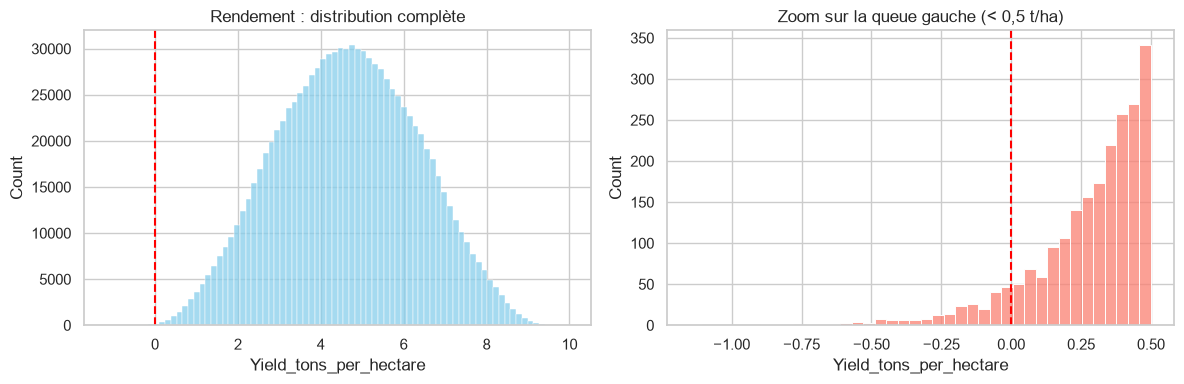

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(crop[TARGET], bins=80, ax=ax[0], color="skyblue")
ax[0].axvline(0, color="red", ls="--"); ax[0].set_title("Rendement : distribution complète")
sns.histplot(crop.loc[crop[TARGET] < 0.5, TARGET], bins=40, ax=ax[1], color="salmon")
ax[1].axvline(0, color="red", ls="--"); ax[1].set_title("Zoom sur la queue gauche (< 0,5 t/ha)")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_negatifs.png", dpi=120); plt.show()

**Interprétation** : les rendements négatifs sont physiquement impossibles. Ils sont très rares et ressemblent à la queue gauche d'un bruit gaussien ajouté à la valeur réelle (le rendement a donc été généré avec du bruit). On les supprime avant l'entraînement et on compte les lignes retirées.

In [25]:
n_before = len(crop)
n_dup = int(crop.duplicated().sum())
n_neg = int((crop.drop_duplicates()[TARGET] < 0).sum())
print(f"Lignes initiales : {n_before:,}")
print(f"Doublons retirés : {n_dup:,}")
print(f"Négatifs retirés : {n_neg:,} ({n_neg / n_before:.4%})")
print(f"Lignes finales   : {len(crop_clean):,}")
assert len(crop_clean) == n_before - n_dup - n_neg

Lignes initiales : 1,000,000
Doublons retirés : 0
Négatifs retirés : 231 (0.0231%)
Lignes finales   : 999,769


## 3. Analyse univariée

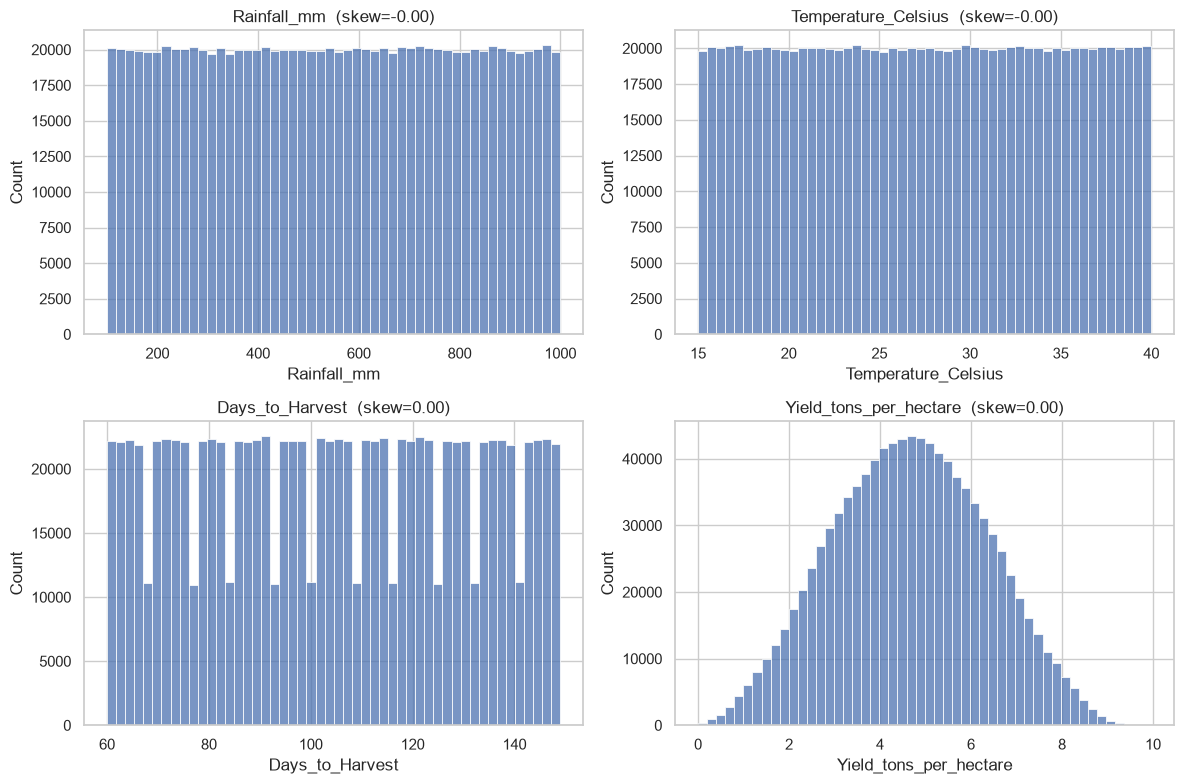

,min,mean,50%,max,std
Rainfall_mm,100.000896,550.077823,550.229205,999.998098,259.804329
Temperature_Celsius,15.000034,27.506079,27.509509,39.999997,7.220488
Days_to_Harvest,60.000000,104.495141,104.000000,149.000000,25.953328
Yield_tons_per_hectare,0.000411,4.650592,4.652333,9.963372,1.695166


In [26]:
num_cols = ["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest", TARGET]
cat_cols = ["Region", "Soil_Type", "Crop", "Weather_Condition"]
bool_cols = ["Fertilizer_Used", "Irrigation_Used"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(crop_clean[c], bins=50, ax=ax)
    ax.set_title(f"{c}  (skew={crop_clean[c].skew():.2f})")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_numeriques.png", dpi=120); plt.show()

crop_clean[num_cols].describe().T[["min", "mean", "50%", "max", "std"]]

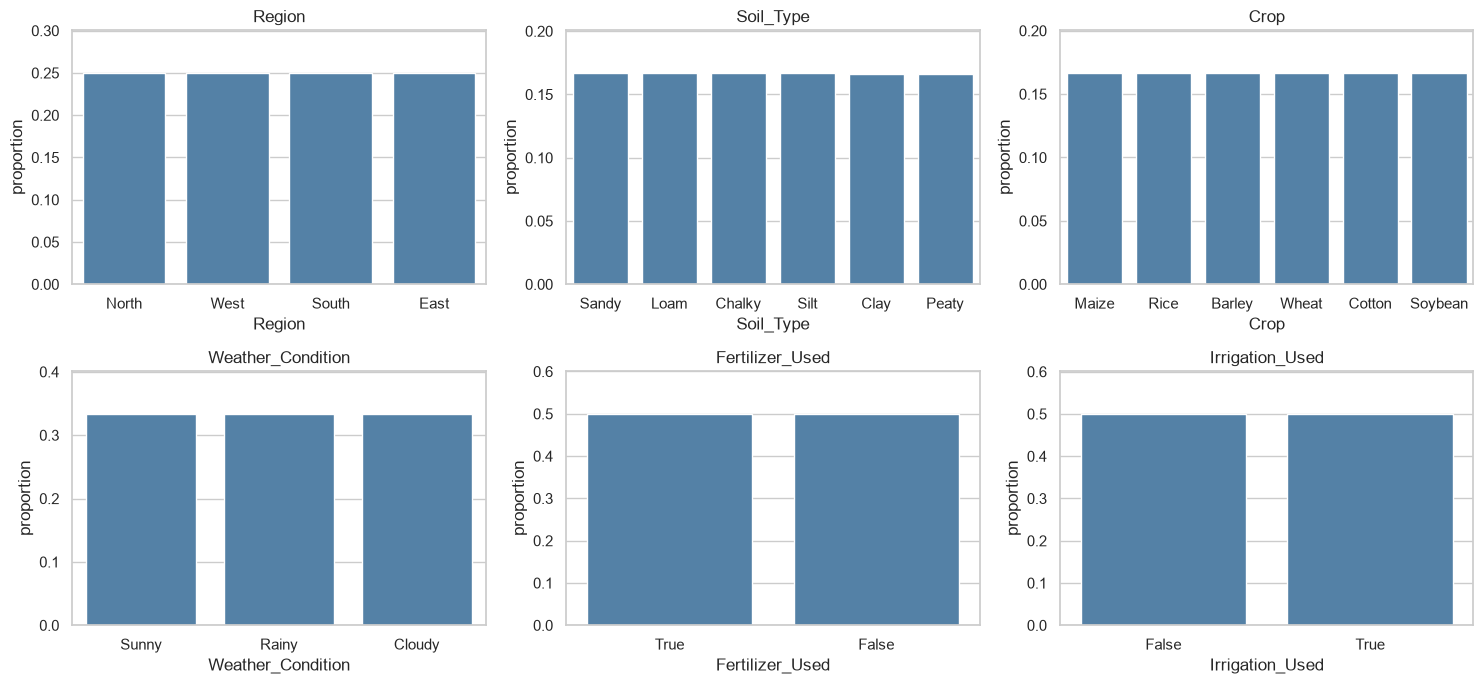

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), cat_cols + bool_cols):
    vc = crop_clean[c].value_counts(normalize=True)
    sns.barplot(x=vc.index.astype(str), y=vc.values, ax=ax, color="steelblue")
    ax.set_title(c); ax.set_ylabel("proportion"); ax.set_ylim(0, max(vc.values) * 1.2)
plt.tight_layout(); plt.savefig(FIG_DIR / "03_categorielles.png", dpi=120); plt.show()

Toutes les catégories sont parfaitement équilibrées (6 cultures ≈ 16,7 % chacune, 4 régions ≈ 25 %, etc.). Il n'y a donc aucun besoin de rééquilibrage ni de pondération.

## 4. Effet de chaque variable sur le rendement

### 4.1 Variables catégorielles

In [28]:
def eta_squared(df, cat, y=TARGET):
    grand = df[y].mean()
    g = df.groupby(cat)[y]
    ssb = (g.count() * (g.mean() - grand) ** 2).sum()
    sst = ((df[y] - grand) ** 2).sum()
    return ssb / sst

rows = []
for c in cat_cols + bool_cols:
    groups = [g[TARGET].values for _, g in crop_clean.groupby(c)]
    h, p = stats.kruskal(*groups)
    rows.append({"variable": c, "eta2": eta_squared(crop_clean, c), "p_kruskal": p,
                 "moy_min": crop_clean.groupby(c)[TARGET].mean().min(),
                 "moy_max": crop_clean.groupby(c)[TARGET].mean().max()})
eta = pd.DataFrame(rows).sort_values("eta2", ascending=False).reset_index(drop=True)
eta

,variable,eta2,p_kruskal,moy_min,moy_max
0,Fertilizer_Used,0.195282,0.000000,3.901402,5.399616
1,Irrigation_Used,0.124931,0.000000,4.051897,5.250231
2,Crop,0.000006,0.361719,4.642513,4.654701
3,Region,0.000003,0.246733,4.646696,4.655298
4,Soil_Type,0.000002,0.848676,4.646091,4.654166
5,Weather_Condition,0.000001,0.404067,4.648262,4.653214


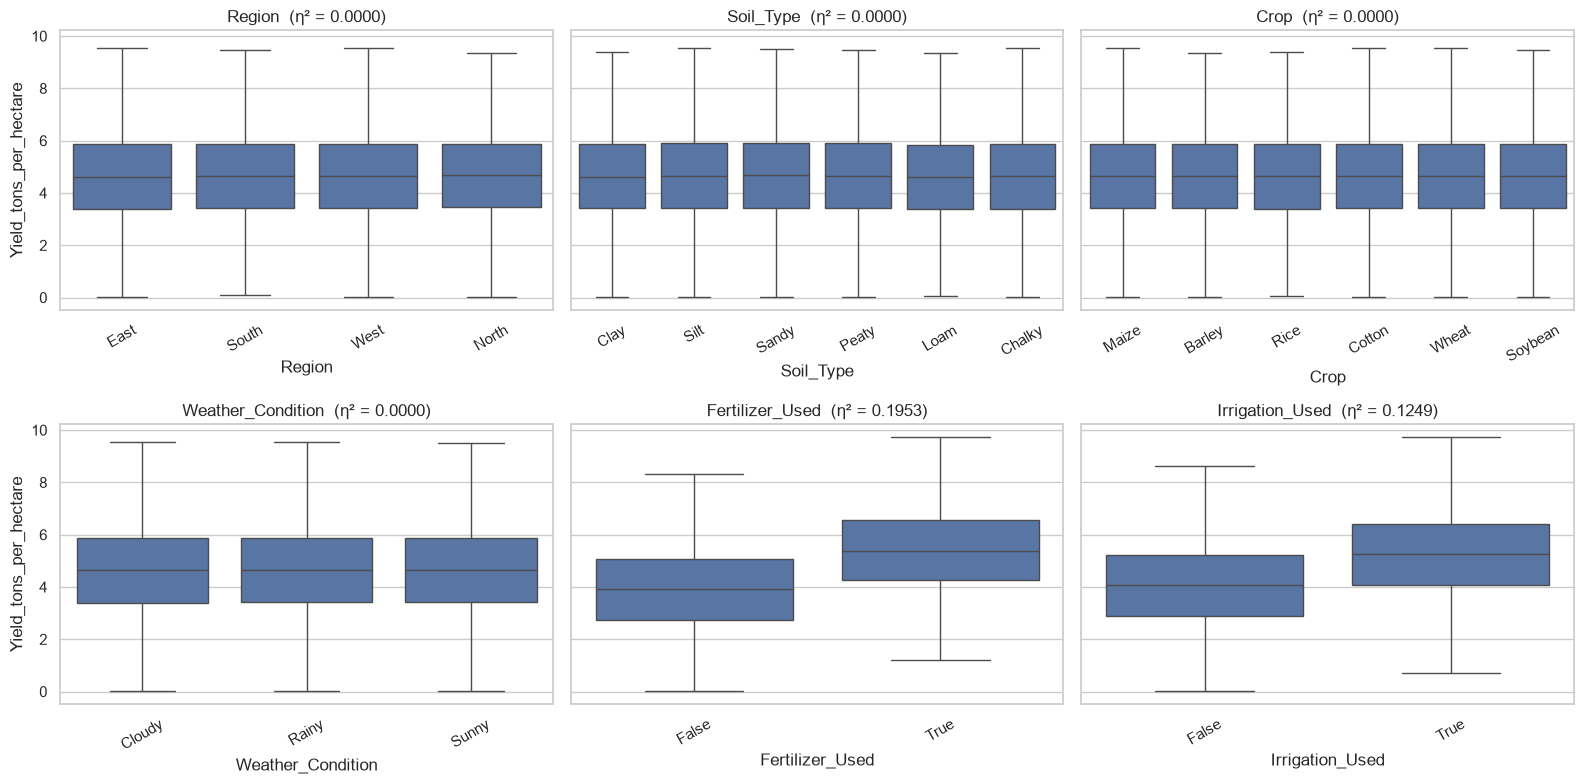

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
for ax, c in zip(axes.ravel(), cat_cols + bool_cols):
    order = crop_clean.groupby(c)[TARGET].mean().sort_values().index
    sns.boxplot(data=crop_clean.sample(100_000, random_state=SEED), x=c, y=TARGET,
                order=order, ax=ax, showfliers=False)
    ax.set_title(f"{c}  (η² = {eta.set_index('variable').loc[c, 'eta2']:.4f})")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(FIG_DIR / "04_boxplots_categorielles.png", dpi=120); plt.show()

**Résultat déterminant pour le projet** : la culture, la région, le type de sol et la météo ont un η² proche de 0 (les rendements moyens diffèrent de quelques millièmes de t/ha). Seules l'utilisation d'engrais et l'irrigation ont un effet réel.

Conséquence directe : la fonction de recommandation (classer les cultures) risque de produire un classement quasi aléatoire. 

### 4.2 Variables numériques

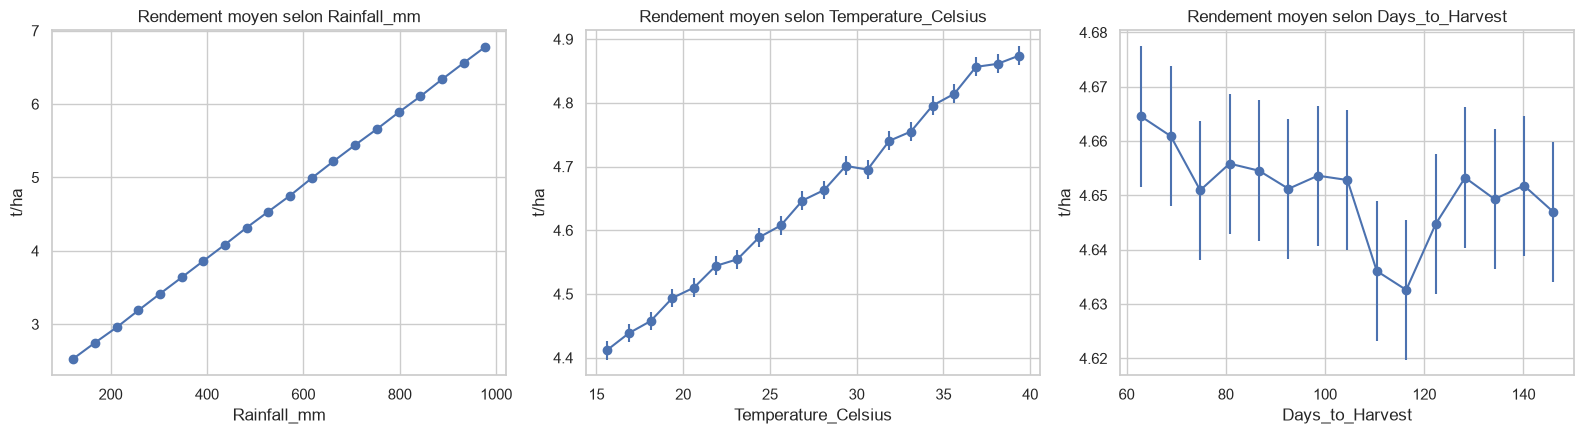

In [30]:
def binned_mean(df, col, bins=20):
    b = pd.cut(df[col], bins=bins)
    out = df.groupby(b, observed=True)[TARGET].agg(["mean", "std", "count"])
    out["centre"] = [i.mid for i in out.index]
    return out

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, c in zip(axes, ["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest"]):
    bm = binned_mean(crop_clean, c, 20 if c != "Days_to_Harvest" else 15)
    ax.errorbar(bm["centre"], bm["mean"], yerr=bm["std"] / np.sqrt(bm["count"]) * 1.96, fmt="o-")
    ax.set_title(f"Rendement moyen selon {c}"); ax.set_xlabel(c); ax.set_ylabel("t/ha")
plt.tight_layout(); plt.savefig(FIG_DIR / "05_numeriques_vs_rendement.png", dpi=120); plt.show()

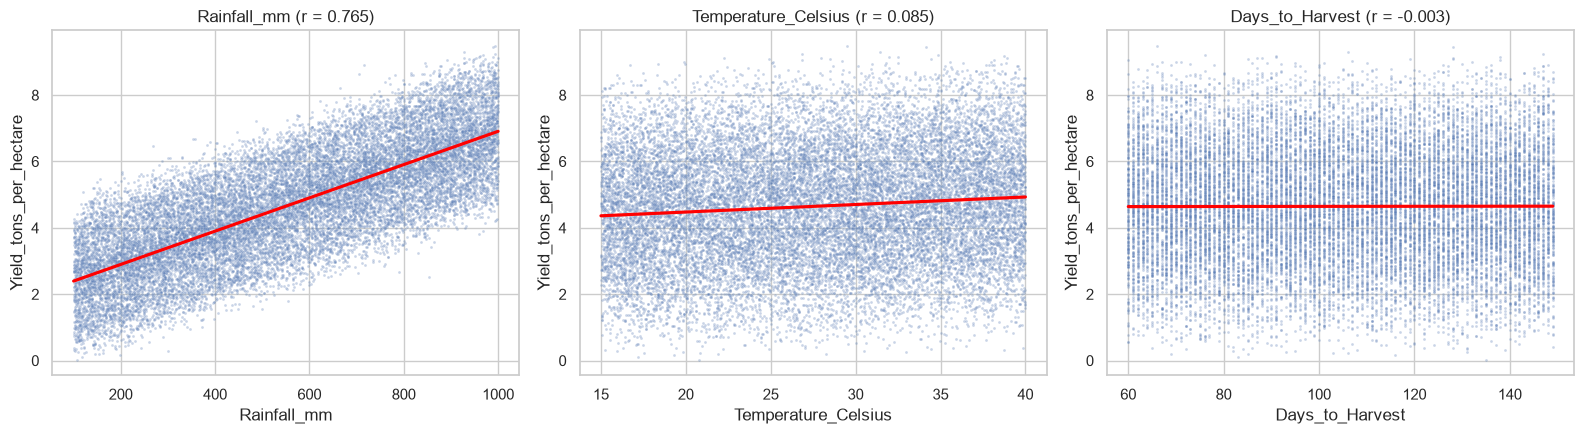

In [31]:
samp = crop_clean.sample(20_000, random_state=SEED)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, c in zip(axes, ["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest"]):
    sns.scatterplot(data=samp, x=c, y=TARGET, s=4, alpha=0.3, ax=ax)
    sns.regplot(data=samp, x=c, y=TARGET, scatter=False, color="red", ax=ax)
    r, _ = stats.pearsonr(crop_clean[c], crop_clean[TARGET])
    ax.set_title(f"{c} (r = {r:.3f})")
plt.tight_layout(); plt.savefig(FIG_DIR / "06_scatter.png", dpi=120); plt.show()

- **Pluie** : relation linéaire croissante et forte (r ≈ 0,76). Pas de plateau ni de seuil visible entre 100 et 1000 mm.
- **Température** : très faible effet positif (r ≈ 0,09).
- **Jours avant récolte** : aucun effet.

## 5. Interactions

Irrigation_Used  False  True 
Fertilizer_Used              
False            3.306  4.499
True             4.800  5.999

Gain engrais seul        : 1.494
Gain irrigation seule    : 1.193
Gain des deux combinés   : 2.693


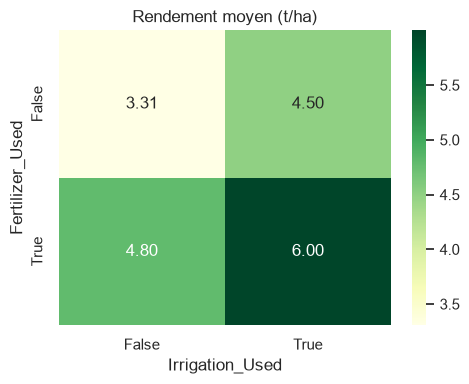

In [32]:
pivot = crop_clean.pivot_table(index="Fertilizer_Used", columns="Irrigation_Used",
                               values=TARGET, aggfunc="mean")
print(pivot.round(3))
print("\nGain engrais seul        :", round(pivot.loc[True, False] - pivot.loc[False, False], 3))
print("Gain irrigation seule    :", round(pivot.loc[False, True] - pivot.loc[False, False], 3))
print("Gain des deux combinés   :", round(pivot.loc[True, True] - pivot.loc[False, False], 3))
plt.figure(figsize=(5, 4)); sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlGn")
plt.title("Rendement moyen (t/ha)"); plt.tight_layout()
plt.savefig(FIG_DIR / "07_engrais_irrigation.png", dpi=120); plt.show()

Les gains sont **additifs** : engrais (≈ +1,5 t/ha) + irrigation (≈ +1,2 t/ha) ≈ gain combiné (≈ +2,7 t/ha). Il n'y a pas d'effet de synergie, donc un modèle linéaire suffit déjà largement à les représenter.

In [33]:
# La culture modifie-t-elle l'effet des conditions ? (interaction culture x condition)
pc = crop_clean.pivot_table(index="Crop", columns=["Fertilizer_Used", "Irrigation_Used"],
                            values=TARGET, aggfunc="mean")
display(pc.round(3))

slopes = {c: np.polyfit(g["Rainfall_mm"], g[TARGET], 1)[0] for c, g in crop_clean.groupby("Crop")}
print("\nPente rendement/pluie par culture (t/ha par mm) :")
print(pd.Series(slopes).round(5))

Fertilizer_Used  False         True        
Irrigation_Used  False  True   False  True 
Crop                                       
Barley           3.305  4.484  4.805  6.007
Cotton           3.306  4.504  4.801  5.994
Maize            3.300  4.500  4.789  5.990
Rice             3.307  4.507  4.802  6.006
Soybean          3.309  4.506  4.792  6.008
Wheat            3.309  4.496  4.808  5.990


Pente rendement/pluie par culture (t/ha par mm) :
Barley     0.00500
Cotton     0.00498
Maize      0.00499
Rice       0.00500
Soybean    0.00499
Wheat      0.00498
dtype: float64


Les 6 cultures réagissent de manière identique (mêmes moyennes, mêmes pentes). Aucune culture n'est avantagée dans certaines conditions : le jeu de données ne contient pas d'information discriminante entre cultures.

## 6. Corrélations et plafond de performance

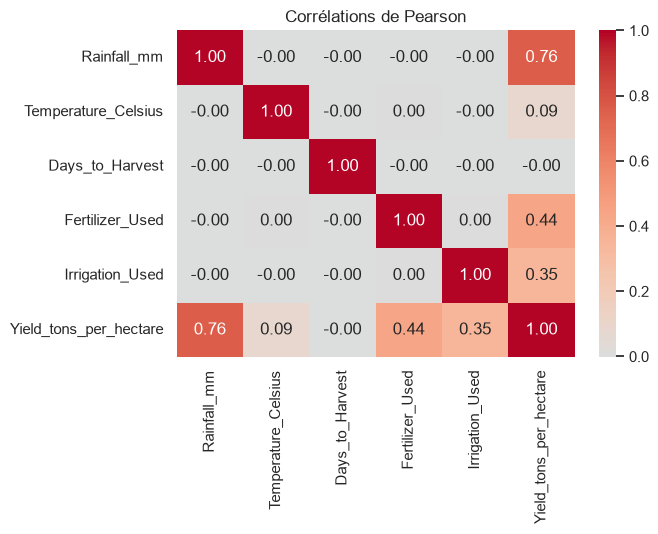

In [34]:
corr_df = crop_clean[["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest"]].copy()
corr_df["Fertilizer_Used"] = crop_clean["Fertilizer_Used"].astype(int)
corr_df["Irrigation_Used"] = crop_clean["Irrigation_Used"].astype(int)
corr_df[TARGET] = crop_clean[TARGET]
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corrélations de Pearson"); plt.tight_layout()
plt.savefig(FIG_DIR / "08_correlations.png", dpi=120); plt.show()

In [35]:
# Régression linéaire de référence avec TOUTES les variables (one-hot)
X = pd.get_dummies(crop_clean.drop(columns=TARGET), drop_first=True).astype(float)
y = crop_clean[TARGET]
lin = LinearRegression().fit(X, y)
resid = y - lin.predict(X)
print(f"R² (linéaire, toutes variables) : {lin.score(X, y):.4f}")
print(f"RMSE : {np.sqrt((resid**2).mean()):.4f} t/ha   |   écart-type du rendement : {y.std():.4f}")
coefs = pd.Series(lin.coef_, X.columns).sort_values(key=abs, ascending=False)
coefs.round(4)

R² (linéaire, toutes variables) : 0.9130
RMSE : 0.5001 t/ha   |   écart-type du rendement : 1.6952


Fertilizer_Used            1.4998
Irrigation_Used            1.1990
Temperature_Celsius        0.0199
Rainfall_mm                0.0050
Soil_Type_Clay             0.0037
Crop_Maize                -0.0031
Crop_Wheat                -0.0029
Soil_Type_Sandy            0.0017
Weather_Condition_Rainy    0.0014
Region_West               -0.0012
Region_North               0.0011
Region_South              -0.0010
Crop_Cotton               -0.0009
Soil_Type_Silt            -0.0009
Crop_Soybean              -0.0009
Soil_Type_Peaty            0.0007
Crop_Rice                  0.0006
Weather_Condition_Sunny    0.0004
Soil_Type_Loam             0.0004
Days_to_Harvest            0.0000
dtype: float64

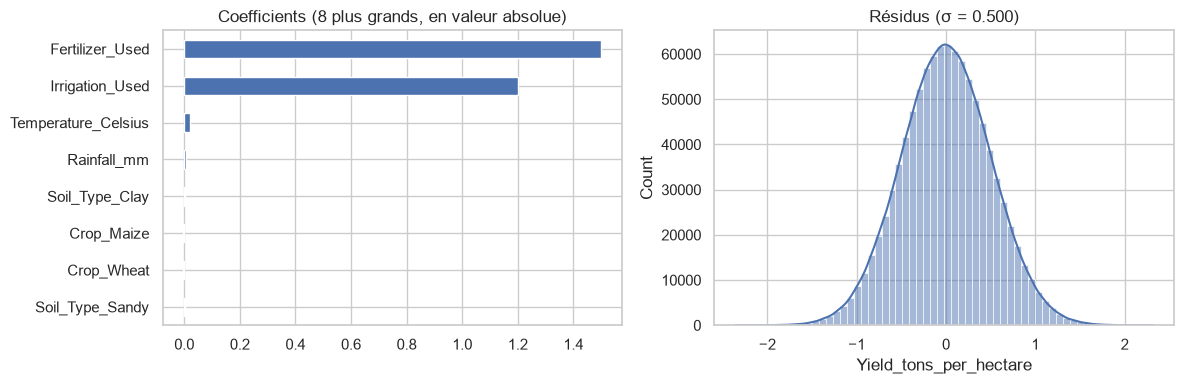

Test de normalité des résidus (skew, kurtosis) : 0.005 -0.005


In [36]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
coefs.head(8).iloc[::-1].plot.barh(ax=ax[0]); ax[0].set_title("Coefficients (8 plus grands, en valeur absolue)")
sns.histplot(resid, bins=60, kde=True, ax=ax[1]); ax[1].set_title(f"Résidus (σ = {resid.std():.3f})")
plt.tight_layout(); plt.savefig(FIG_DIR / "09_regression_reference.png", dpi=120); plt.show()
print("Test de normalité des résidus (skew, kurtosis) :", round(resid.skew(), 3), round(resid.kurt(), 3))

**Plafond de performance** : un simple modèle linéaire atteint déjà R² ≈ 0,91, et les résidus sont un bruit gaussien de σ ≈ 0,5 t/ha, indépendant des variables. Ce bruit est irréductible : aucun modèle (Random Forest, XGBoost…) ne pourra faire significativement mieux. Les modèles non linéaires serviront surtout à confirmer ce plafond ; il faut s'attendre à des écarts de R² de l'ordre de 0,001 entre modèles.

## 7. Analyse en composantes principales (ACP)

On réalise l'ACP sur les variables quantitatives et binaires (standardisées). On l'applique deux fois : (a) sur les variables explicatives seules, (b) avec le rendement inclus, pour voir quelles variables sont associées au rendement.

In [37]:
feat = corr_df.drop(columns=TARGET)
Xs = StandardScaler().fit_transform(feat)
pca_a = PCA().fit(Xs)
print("(a) Variance expliquée, variables explicatives seules :")
print(pd.Series(pca_a.explained_variance_ratio_, index=[f"PC{i+1}" for i in range(Xs.shape[1])]).round(3))

(a) Variance expliquée, variables explicatives seules :
PC1    0.201
PC2    0.201
PC3    0.200
PC4    0.199
PC5    0.199
dtype: float64


In [38]:
full = corr_df.copy()
Xf = StandardScaler().fit_transform(full)
pca = PCA().fit(Xf)
evr = pca.explained_variance_ratio_
names = [f"PC{i+1}" for i in range(len(evr))]
print("(b) Variance expliquée, avec le rendement :")
print(pd.Series(evr, index=names).round(3))

loadings = pd.DataFrame(pca.components_.T, index=full.columns, columns=names)
# corrélations variables-composantes (cercle des corrélations)
cor_vc = loadings * np.sqrt(pca.explained_variance_)
cor_vc.round(3)

(b) Variance expliquée, avec le rendement :
PC1    0.326
PC2    0.167
PC3    0.167
PC4    0.167
PC5    0.166
PC6    0.007
dtype: float64


,PC1,PC2,PC3,PC4,PC5,PC6
Rainfall_mm,0.791,-0.555,-0.206,0.079,0.060,-0.119
Temperature_Celsius,0.089,0.444,-0.650,0.053,0.608,-0.013
Days_to_Harvest,-0.006,0.042,0.293,0.933,0.202,-0.000
Fertilizer_Used,0.457,0.641,-0.052,0.119,-0.599,-0.069
Irrigation_Used,0.366,0.292,0.669,-0.325,0.474,-0.055
Yield_tons_per_hectare,0.989,-0.000,0.001,0.003,0.000,0.149


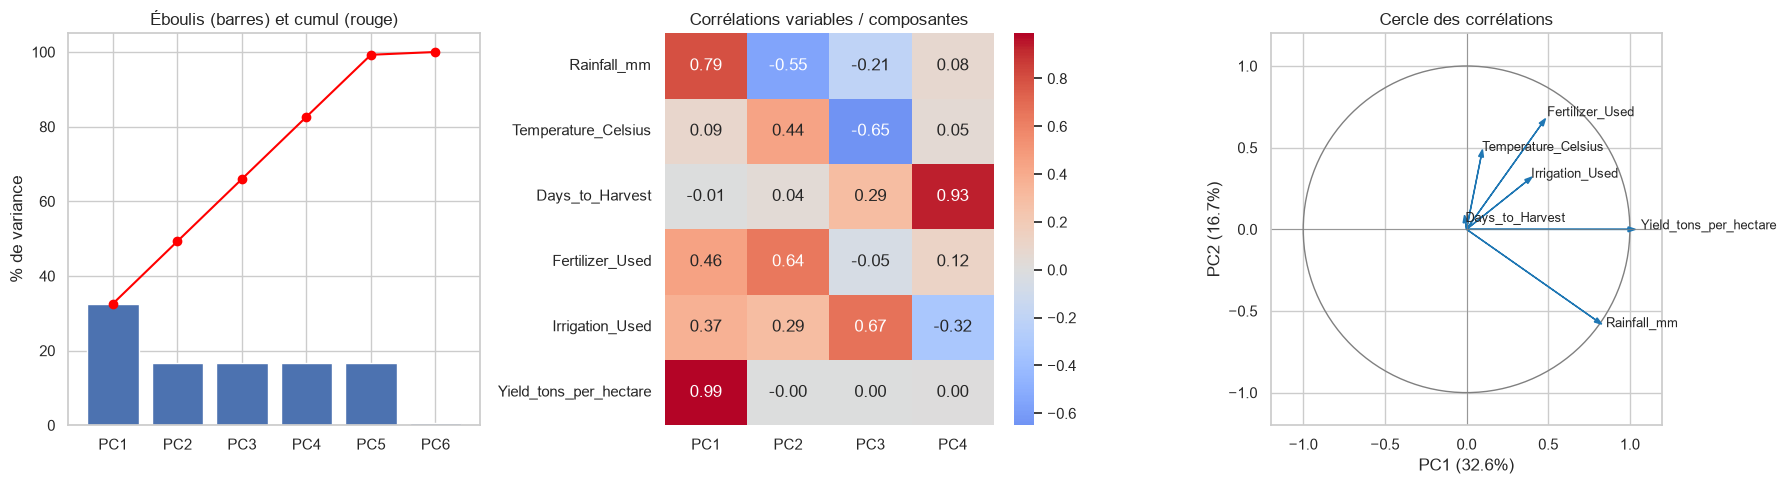

In [39]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].bar(names, evr * 100); ax[0].plot(names, np.cumsum(evr) * 100, "o-", color="red")
ax[0].set_ylabel("% de variance"); ax[0].set_title("Éboulis (barres) et cumul (rouge)")

sns.heatmap(cor_vc.iloc[:, :4], annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1])
ax[1].set_title("Corrélations variables / composantes")

circle = plt.Circle((0, 0), 1, fill=False, color="grey"); ax[2].add_patch(circle)
for v in full.columns:
    x, y_ = cor_vc.loc[v, "PC1"], cor_vc.loc[v, "PC2"]
    ax[2].arrow(0, 0, x, y_, head_width=0.03, color="tab:blue")
    ax[2].text(x * 1.08, y_ * 1.08, v, fontsize=9)
ax[2].set_xlim(-1.2, 1.2); ax[2].set_ylim(-1.2, 1.2); ax[2].axhline(0, c="grey", lw=.5); ax[2].axvline(0, c="grey", lw=.5)
ax[2].set_xlabel(f"PC1 ({evr[0]:.1%})"); ax[2].set_ylabel(f"PC2 ({evr[1]:.1%})"); ax[2].set_title("Cercle des corrélations")
ax[2].set_aspect("equal")
plt.tight_layout(); plt.savefig(FIG_DIR / "10_acp.png", dpi=120); plt.show()

**Lecture de l'ACP**
- (a) Sur les variables explicatives seules, chaque composante explique ≈ 1/5 de la variance : les variables sont indépendantes, aucune redondance à compresser. L'ACP ne sert donc pas à réduire la dimension ici, mais à identifier les variables liées au rendement.
- (b) Avec le rendement, PC1 regroupe le rendement, la pluie, l'engrais et l'irrigation : ce sont les variables clés. La température n'y contribue que faiblement et les jours avant récolte pas du tout.
- Les variables catégorielles (culture, région, sol, météo) ne figurent pas dans l'ACP (non numériques) ; leur absence d'effet est établie par l'η² de la section 4.

## 8. Validation sur `yield_df` (CropYield Prediction)

Rappel : `yield_df` est une table pays x année x culture (pesticides = total national, pas une dose par parcelle). Elle sert à **valider** (ordres de grandeur, effet du climat), pas à entraîner.

In [40]:
yd = yield_df.rename(columns={"hg/ha_yield": "yield_hg_ha", "average_rain_fall_mm_per_year": "rain_mm",
                              "pesticides_tonnes": "pesticides_t", "avg_temp": "temp_c"})
n_dup_yd = int(yd.duplicated().sum())
yd = yd.drop_duplicates().reset_index(drop=True)
print(f"Doublons exacts retirés de yield_df : {n_dup_yd:,}")
yd["yield_t_ha"] = yd["yield_hg_ha"] / 10_000   # 1 t/ha = 10 000 hg/ha
print(yd.shape, "| pays :", yd["Area"].nunique(), "| années :", yd["Year"].min(), "-", yd["Year"].max())
print("Valeurs manquantes :", int(yd.isna().sum().sum()))
yd.describe().T[["min", "mean", "50%", "max"]].round(2)

Doublons exacts retirés de yield_df : 2,310
(25932, 8) | pays : 101 | années : 1990 - 2013
Valeurs manquantes : 0


,min,mean,50%,max
Year,1990.00,2001.56,2001.00,2013.00
yield_hg_ha,50.00,76978.13,39530.00,501412.00
rain_mm,51.00,1146.84,1083.00,3240.00
pesticides_t,0.04,34782.57,15373.00,367778.00
temp_c,1.30,20.42,21.42,30.65
yield_t_ha,0.00,7.70,3.95,50.14


In [41]:
# Harmonisation des noms de cultures (mentor : Rice <-> Rice, paddy ; Soybean <-> Soybeans)
CROP_MAP = {"Maize": "Maize", "Wheat": "Wheat", "Rice, paddy": "Rice", "Soybeans": "Soybean"}
yd["Crop"] = yd["Item"].map(CROP_MAP)
common = yd.dropna(subset=["Crop"]).copy()
print("Cultures de yield_df :", sorted(yd["Item"].unique()))
print("Cultures communes    :", sorted(common["Crop"].unique()))
print("Absentes de yield_df :", sorted(set(crop_clean["Crop"]) - set(common["Crop"])))
print(f"Lignes communes : {len(common):,} / {len(yd):,}")

Cultures de yield_df : ['Cassava', 'Maize', 'Plantains and others', 'Potatoes', 'Rice, paddy', 'Sorghum', 'Soybeans', 'Sweet potatoes', 'Wheat', 'Yams']
Cultures communes    : ['Maize', 'Rice', 'Soybean', 'Wheat']
Absentes de yield_df : ['Barley', 'Cotton']
Lignes communes : 13,394 / 25,932


In [42]:
cmp_yield = pd.concat([
    crop_clean[crop_clean["Crop"].isin(common["Crop"].unique())].groupby("Crop")[TARGET].agg(["mean", "std", "min", "max"]).add_prefix("parcelle_"),
    common.groupby("Crop")["yield_t_ha"].agg(["mean", "std", "min", "max"]).add_prefix("pays_"),
], axis=1).round(2)
cmp_yield

,parcelle_mean,parcelle_std,parcelle_min,parcelle_max,pays_mean,pays_std,pays_min,pays_max
Crop,,,,,,,,
Maize,4.64,1.69,0.01,9.95,3.71,2.82,0.08,20.76
Rice,4.65,1.70,0.00,9.96,4.13,1.96,0.20,10.39
Soybean,4.65,1.70,0.00,9.68,1.70,0.77,0.00,4.16
Wheat,4.65,1.69,0.01,9.80,3.01,1.86,0.17,9.94


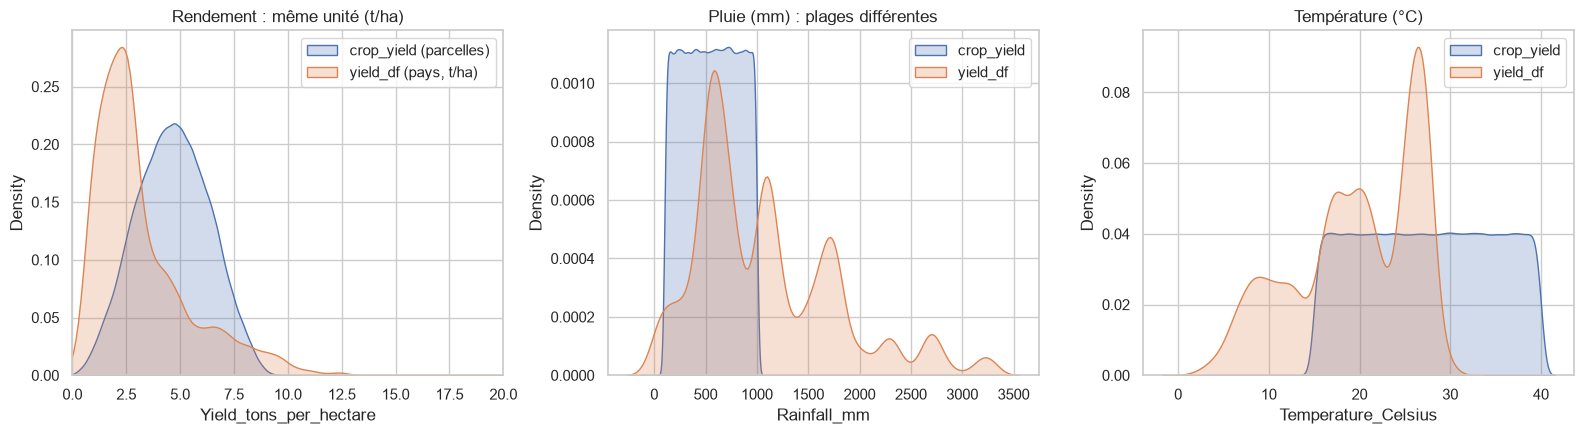

In [43]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
cc = crop_clean[crop_clean["Crop"].isin(common["Crop"].unique())]
sns.kdeplot(cc[TARGET], ax=ax[0], label="crop_yield (parcelles)", fill=True)
sns.kdeplot(common["yield_t_ha"], ax=ax[0], label="yield_df (pays, t/ha)", fill=True)
ax[0].set_title("Rendement : même unité (t/ha)"); ax[0].legend(); ax[0].set_xlim(0, 20)
sns.kdeplot(cc["Rainfall_mm"], ax=ax[1], label="crop_yield", fill=True)
sns.kdeplot(common["rain_mm"], ax=ax[1], label="yield_df", fill=True)
ax[1].set_title("Pluie (mm) : plages différentes"); ax[1].legend()
sns.kdeplot(cc["Temperature_Celsius"], ax=ax[2], label="crop_yield", fill=True)
sns.kdeplot(common["temp_c"], ax=ax[2], label="yield_df", fill=True)
ax[2].set_title("Température (°C)"); ax[2].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "11_comparaison_datasets.png", dpi=120); plt.show()

**Constats de cohérence**
- Rendement : après conversion en t/ha, les rendements nationaux (yield_df) sont inférieurs aux rendements parcelle (crop_yield) pour les 4 cultures communes, et l'écart est très variable (Maize 3,6 contre 4,6 ; Soybean 1,7 contre 4,6). Les rendements simulés de `crop_yield` sont identiques d'une culture à l'autre, alors que les vrais rendements diffèrent fortement selon la culture.
- Pluie : `crop_yield` couvre 100-1000 mm, `yield_df` jusqu'à ≈ 3 000 mm/an. Les plages ne se recouvrent que partiellement : `yield_df` ne peut pas servir à étendre le modèle hors de sa plage.
- Température : plages proches, mais `yield_df` est une moyenne annuelle nationale.


In [44]:
# Le climat est-il lié au rendement dans yield_df ? (corrélations par culture, + pesticides)
rows = []
for crop_name, g in common.groupby("Crop"):
    rows.append({"Crop": crop_name,
                 "r_pluie": g["rain_mm"].corr(g["yield_t_ha"]),
                 "r_temp": g["temp_c"].corr(g["yield_t_ha"]),
                 "r_pesticides": g["pesticides_t"].corr(g["yield_t_ha"]),
                 "r_pesticides_log": np.log1p(g["pesticides_t"]).corr(g["yield_t_ha"]),
                 "n": len(g)})
val = pd.DataFrame(rows).set_index("Crop").round(3)
val

,r_pluie,r_temp,r_pesticides,r_pesticides_log,n
Crop,,,,,
Maize,-0.190,-0.549,0.087,0.253,3824
Rice,-0.157,-0.384,0.113,0.371,3091
Soybean,-0.062,-0.395,0.353,0.419,2940
Wheat,-0.068,-0.366,-0.038,0.150,3539


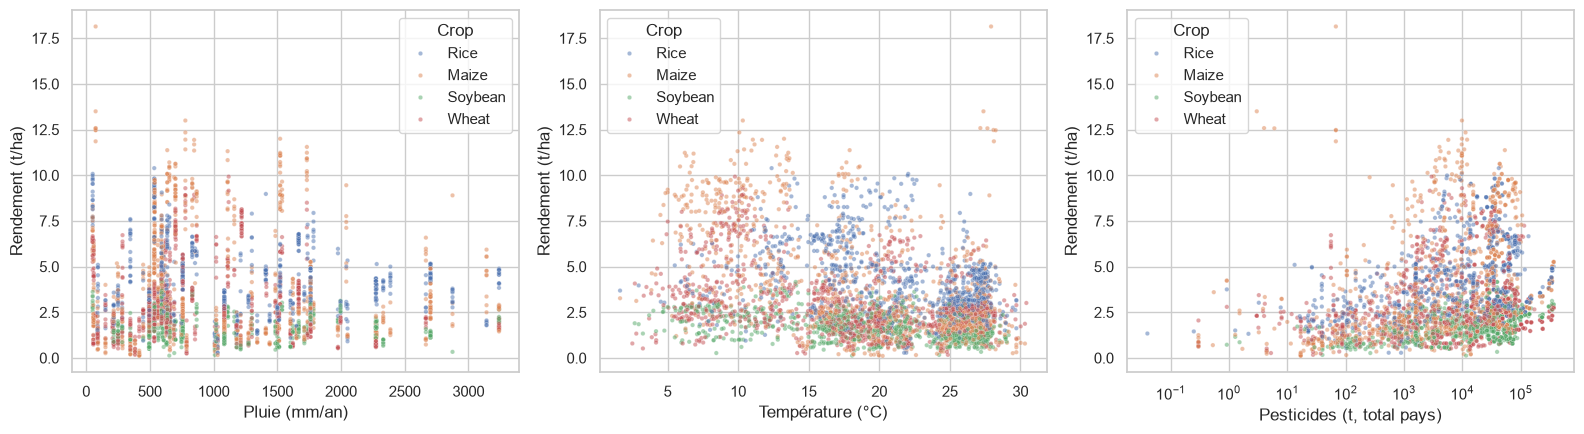

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (c, lab) in zip(axes, [("rain_mm", "Pluie (mm/an)"), ("temp_c", "Température (°C)"), ("pesticides_t", "Pesticides (t, total pays)")]):
    sns.scatterplot(data=common.sample(4000, random_state=SEED), x=c, y="yield_t_ha", hue="Crop", s=10, alpha=.5, ax=ax)
    ax.set_xlabel(lab); ax.set_ylabel("Rendement (t/ha)")
    if c == "pesticides_t": ax.set_xscale("log")
plt.tight_layout(); plt.savefig(FIG_DIR / "12_yield_df_climat.png", dpi=120); plt.show()

**Validation (résultat important)** : dans `yield_df`, les corrélations avec le climat sont **différentes, et même opposées** à celles de `crop_yield` : la température est corrélée **négativement** au rendement (r ≈ -0,4 à -0,5 selon la culture), la pluie très faiblement (r entre -0,19 et -0,06), alors que dans `crop_yield` la pluie a un effet fort positif (r ≈ +0,76) et la température un léger effet positif.

Ces corrélations brutes sont toutefois **confondues** par le pays : les pays chauds sont aussi ceux dont les rendements sont plus faibles (moins de moyens, sols différents), ce qui ne dit rien de l'effet agronomique de la chaleur. Ce que l'on peut retenir : (1) le niveau de rendement dépend avant tout du pays, (2) les deux jeux de données ne se confirment pas mutuellement sur le climat. Les données `crop_yield` sont synthétiques, et leurs coefficients ne doivent pas être présentés comme des lois agronomiques réelles.

Les pesticides de `yield_df` sont un **total par pays et par année** : ils ne sont pas comparables à une dose par parcelle, donc exclus du modèle (avis du mentor).

In [46]:
# Effet "pays" : part de variance du rendement expliquée par le pays dans yield_df
print(f"η² pays dans yield_df : {eta_squared(common, 'Area', 'yield_t_ha'):.3f}")
print(f"η² culture dans yield_df : {eta_squared(common, 'Crop', 'yield_t_ha'):.3f}")

η² pays dans yield_df : 0.437
η² culture dans yield_df : 0.156


Dans `yield_df`, **le pays** (η² ≈ 0,4) et, dans une moindre mesure, la culture (η² ≈ 0,15) expliquent une grande part de la variance, contrairement à `crop_yield` où la culture n'a aucun effet. Les deux jeux de données ne racontent donc pas la même histoire sur le rôle de la culture.

## 9. Synthèse et export

In [47]:
summary = pd.DataFrame({
    "variable": ["Rainfall_mm", "Fertilizer_Used", "Irrigation_Used", "Temperature_Celsius",
                 "Days_to_Harvest", "Crop", "Region", "Soil_Type", "Weather_Condition"],
    "effet_sur_rendement": ["Fort (+0,005 t/ha par mm)", "Fort (+1,5 t/ha)", "Fort (+1,2 t/ha)",
                            "Très faible (+0,02 t/ha par °C)", "Nul", "Nul", "Nul", "Nul", "Nul"],
})
summary

,variable,effet_sur_rendement
0,Rainfall_mm,"Fort (+0,005 t/ha par mm)"
1,Fertilizer_Used,"Fort (+1,5 t/ha)"
2,Irrigation_Used,"Fort (+1,2 t/ha)"
3,Temperature_Celsius,"Très faible (+0,02 t/ha par °C)"
4,Days_to_Harvest,Nul
5,Crop,Nul
6,Region,Nul
7,Soil_Type,Nul
8,Weather_Condition,Nul


In [48]:
out = DATA_PROCESSED / "crop_yield_clean.csv"
crop_clean.to_csv(out, index=False)
print(f"Dataset propre exporté : {out}  ({len(crop_clean):,} lignes, {crop_clean.shape[1]} colonnes)")
common[["Area", "Year", "Crop", "yield_t_ha", "rain_mm", "temp_c", "pesticides_t"]].to_csv(
    DATA_PROCESSED / "yield_df_validation.csv", index=False)

Dataset propre exporté : ..\data\processed\crop_yield_clean.csv  (999,769 lignes, 10 colonnes)


### Conclusions à retenir
1. **Données propres** : `crop_yield` sans manquant ni doublon, 231 rendements négatifs supprimés (≈ 0,02 %) ; `yield_df` avec 2 310 doublons exacts retirés. 
2. **Variables clés** (ACP + corrélations + η²) : pluie, engrais, irrigation. La température a un effet marginal.
3. **Variables sans effet** : culture, région, sol, météo, jours avant récolte.
4. **Plafond** : R² ≈ 0,91 avec un simple modèle linéaire ; le reste est un bruit irréductible (σ ≈ 0,5 t/ha).
5. **Les deux jeux de données ne concordent pas sur le climat** (signe de la température opposé) : `yield_df` valide les ordres de grandeur, pas les coefficients.
6. **Pesticides** : non utilisés dans le modèle (totaux nationaux).